In [4]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

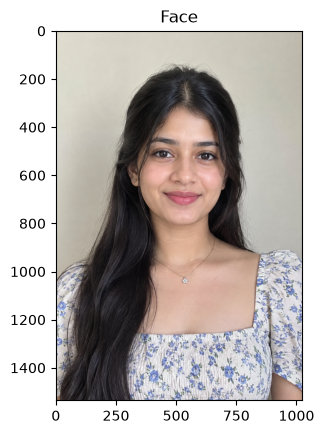

In [5]:
# Load the Face Image
faceImage = cv2.imread('08.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")

In [6]:
faceImage.shape

(1536, 1024, 3)

In [7]:
#resized_faceImage.shape
faceImage.shape

(1536, 1024, 3)

Text(0.5, 1.0, 'glassPNG')

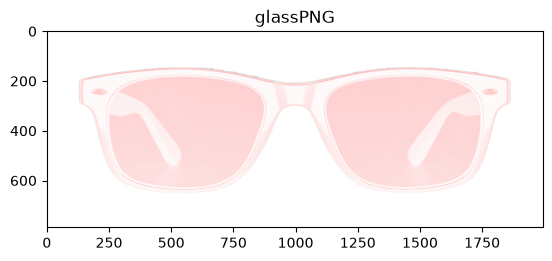

In [8]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [9]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(114,30))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(30, 114, 4)


In [13]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,:3]
glassMask = cv2.cvtColor(glassBGR,cv2.COLOR_BGR2GRAY)
glassMask = cv2.threshold(glassMask, 10, 225, cv2. THRESH_BINARY)[1]

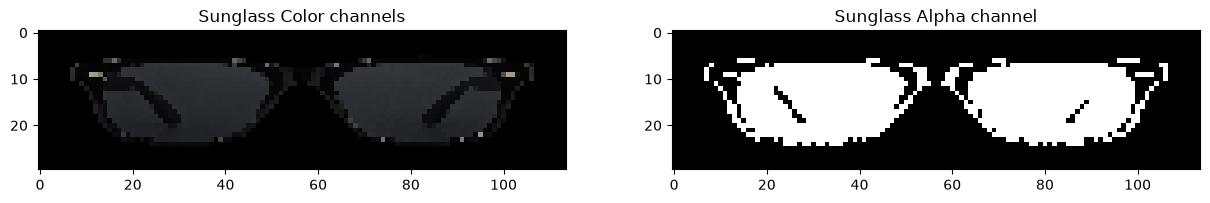

In [15]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask,cmap='gray');plt.title('Sunglass Alpha channel');

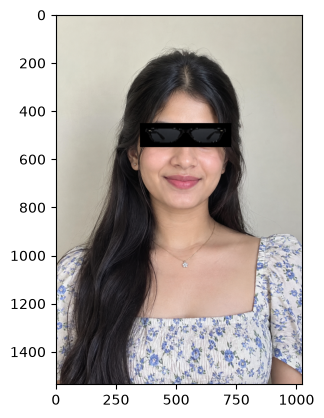

In [22]:
# Make a copy
#faceWithGlassesNaive = resized_faceImage.copy()
faceWithGlassesNaive = faceImage.copy()
glassResized = cv2.resize(glassBGR,(380, 100))

# Replace the eye region with the sunglass image
faceWithGlassesNaive[450:550 , 350:730]=glassResized

plt.imshow(faceWithGlassesNaive[...,::-1])

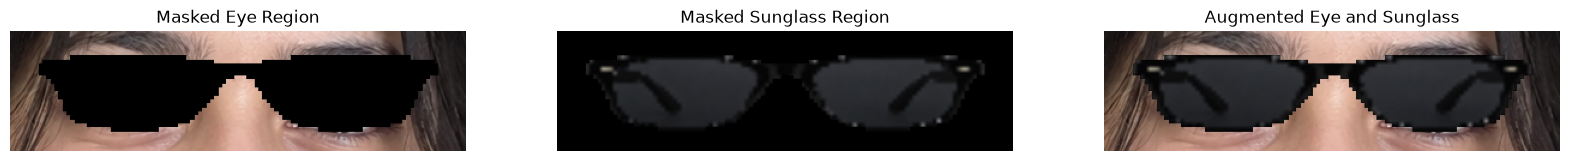

In [28]:
# ---------------------------------------
# CREATE THE ARITHMETIC OVERLAY
# ---------------------------------------

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region
eyeROI = faceWithGlassesArithmetic[450:550, 350:730]

# Resize sunglasses
glassResized = cv2.resize(glassBGR, (380, 100))

# ---------------------------------------
# CREATE MASK FROM PNG ALPHA CHANNEL
# ---------------------------------------

# Take the alpha channel from the original PNG
glassMask = glassPNG[:, :, 3]

# Resize mask to match sunglasses
glassMask = cv2.resize(
    glassMask,
    (380, 100),
    interpolation=cv2.INTER_NEAREST
)

# Convert mask to 0 and 1
glassMask = np.uint8(glassMask > 127)

# Convert to 3 channels
glassMask = cv2.merge(
    (glassMask, glassMask, glassMask)
)

# ---------------------------------------
# MASKED EYE REGION
# ---------------------------------------

maskedEye = cv2.multiply(
    eyeROI,
    1 - glassMask
)

# ---------------------------------------
# MASKED SUNGLASS REGION
# ---------------------------------------

maskedGlass = cv2.multiply(
    glassResized,
    glassMask
)

# ---------------------------------------
# COMBINE
# ---------------------------------------

eyeROIFinal = cv2.add(
    maskedEye,
    maskedGlass
)

# Put the result back into the face
faceWithGlassesArithmetic[
    450:550,
    350:730
] = eyeROIFinal

# ---------------------------------------
# DISPLAY LIKE YOUR REFERENCE
# ---------------------------------------

plt.figure(figsize=(20, 5))

plt.subplot(131)
plt.imshow(maskedEye[..., ::-1])
plt.title("Masked Eye Region")
plt.axis("off")

plt.subplot(132)
plt.imshow(maskedGlass[..., ::-1])
plt.title("Masked Sunglass Region")
plt.axis("off")

plt.subplot(133)
plt.imshow(eyeROIFinal[..., ::-1])
plt.title("Augmented Eye and Sunglass")
plt.axis("off")

plt.show()

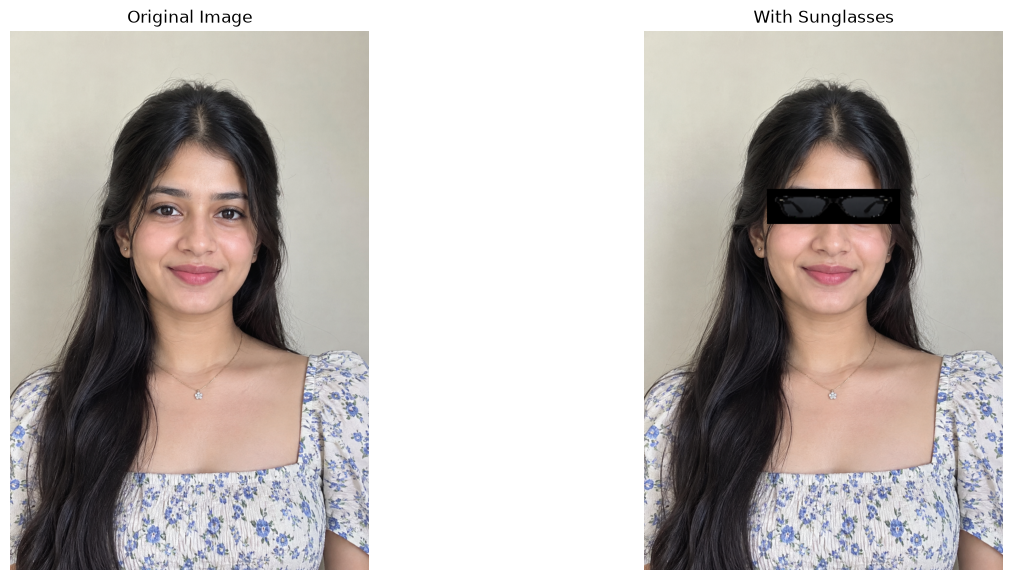

In [30]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()
glassResized = cv2.resize(glassBGR, (380, 100))

# Replace eye region with sunglasses
faceWithGlassesNaive[450:550, 350:730] = glassResized

# Display original and with sunglasses
plt.figure(figsize=(15, 7))

plt.subplot(121)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(122)
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("With Sunglasses")
plt.axis("off")

plt.show()